# **GOIT-DS-HW-09. K-means classification**

---



## **Step 1**

In [1]:
#  STEP 1

# Unzip your files before work with K-means classification.
# If you have already unzipped your files you can skip this step.

import zipfile
import sys
import os

PATH = "data.zip"
TARGET_DIR = "./data"

if os.path.exists(TARGET_DIR):
    print(f"Data is already unzipped (directory '{TARGET_DIR}' exists)")
else:
  try:
      print("Start unzipping...")
      with zipfile.ZipFile(PATH, "r") as zip_ref:
          zip_ref.extractall()
      print("Unzipping completed successfully!")

  except FileNotFoundError:
      raise FileNotFoundError(f"File not found at path: '{PATH}'")

  except zipfile.BadZipFile:
      raise ValueError("Error while unzipping: The file is corrupted or not a valid ZIP archive.")

  finally:
      print("Unzipping process finished.")


Start unzipping...
Unzipping completed successfully!
Unzipping process finished.


## **Step 2**

In [8]:
# STEP 2
# Import everything you need.

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

## **Step 3**

In [3]:
# STEP 3
# Let's import our files in pandas

# 2d dataset
df_2d = pd.read_csv("./data/data_2d.csv")
X_2d = df_2d.values

# MNIST dataset
df_mnist = pd.read_csv("./data/mnist.csv")
X_mnist = df_mnist.values

## **Step 4 (for 2D Dataset)**

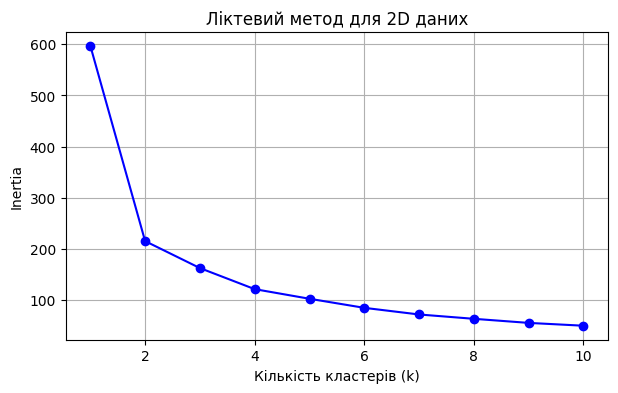

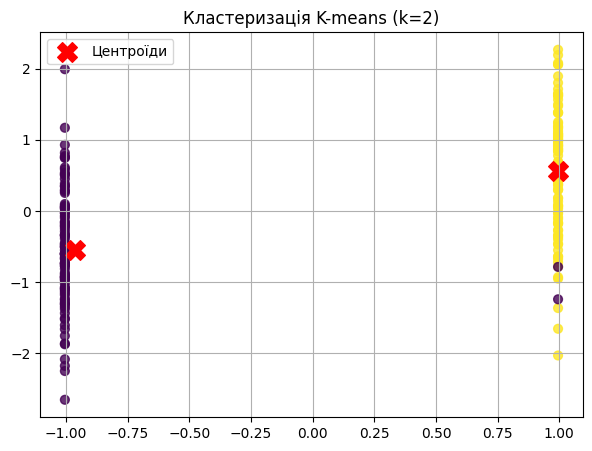

In [9]:
# STEP 4
# Let`s use K-means for our 2d dataset

inertia_2d = []
K_range = range(1, 11)

scaler = StandardScaler()
X_2d_scaled = scaler.fit_transform(X_2d)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_2d_scaled)
  inertia_2d.append(kmeans.inertia_)

# Graph

plt.figure(figsize=(7, 4))
plt.plot(K_range, inertia_2d, marker='o', color='b')
plt.title('Ліктевий метод для 2D даних')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()


optimal_k_2d = 2
kmeans_2d = KMeans(n_clusters=optimal_k_2d, random_state=42, n_init=10)
labels_2d = kmeans_2d.fit_predict(X_2d_scaled)

# Visualising 2D cluster

plt.figure(figsize=(7, 5))
plt.scatter(X_2d_scaled[:, 0], X_2d_scaled[:, 1], c=labels_2d, cmap='viridis', s=40, alpha=0.8)
plt.scatter(kmeans_2d.cluster_centers_[:, 0], kmeans_2d.cluster_centers_[:, 1],
            s=200, c='red', marker='X', label='Центроїди')
plt.title(f'Кластеризація K-means (k={optimal_k_2d})')
plt.legend()
plt.grid(True)
plt.show()

## **Step 5 (for MNIST dataset)**

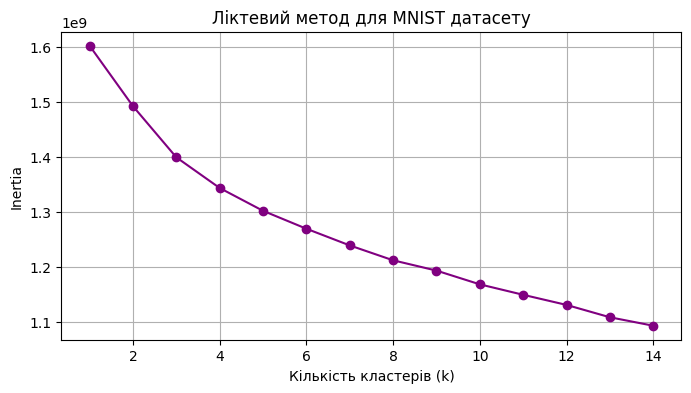

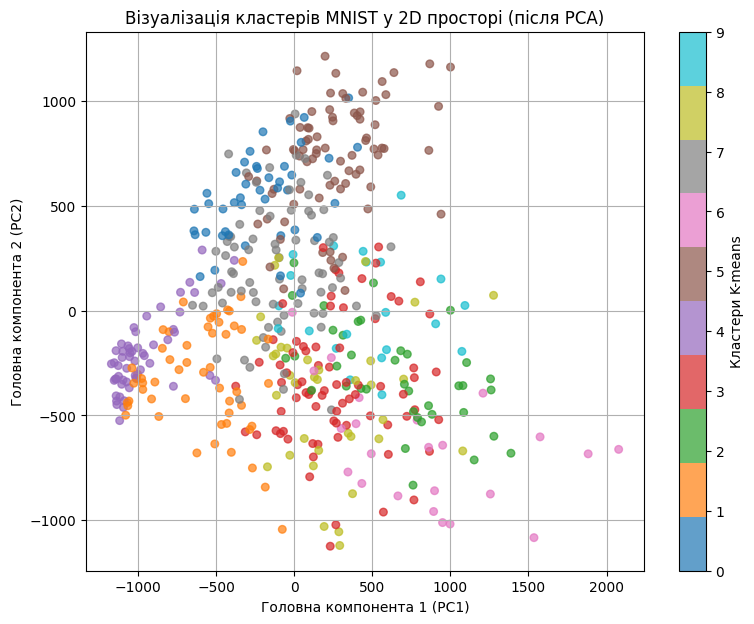

In [11]:
# STEP 5

inertia_mnist = []
K_range_mnist = range(1, 15)

for k in K_range_mnist:
    kmeans_m = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_m.fit(X_mnist)
    inertia_mnist.append(kmeans_m.inertia_)

# Graph
plt.figure(figsize=(8, 4))
plt.plot(K_range_mnist, inertia_mnist, marker='o', color='purple')
plt.title('Ліктевий метод для MNIST датасету')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()


optimal_k_mnist = 10
kmeans_mnist = KMeans(n_clusters=optimal_k_mnist, random_state=42, n_init=10)
labels_mnist = kmeans_mnist.fit_predict(X_mnist)

pca = PCA(n_components=2, random_state=42)
X_mnist_pca = pca.fit_transform(X_mnist)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_mnist_pca[:, 0], X_mnist_pca[:, 1], c=labels_mnist, cmap='tab10', s=30, alpha=0.7)
plt.colorbar(scatter, label='Кластери K-means')
plt.title('Візуалізація кластерів MNIST у 2D просторі (після PCA)')
plt.xlabel('Головна компонента 1 (PC1)')
plt.ylabel('Головна компонента 2 (PC2)')
plt.grid(True)
plt.show()